# Numerical experiments for the spiked Haar model

This notebook reproduces the numerical experiments of the paper on the
fluctuations of sample eigenvalues in the spiked Haar covariance model.

**Model.** $A, B$ are deterministic Hermitian PSD matrices of fixed ranks
$r, s$ with non-zero eigenvalues $\alpha_1, \ldots, \alpha_r$ and
$\beta_1, \ldots, \beta_s$. $O$ is Haar on $O(p)$ (real case, $\mathbb{F}=\mathbb{R}$)
or $U(p)$ (complex case, $\mathbb{F}=\mathbb{C}$). The population covariance is
$$\Sigma = A + O B O^* + \sigma^2 I_p.$$
We draw $n$ iid Gaussian vectors $x_k \sim \mathcal{N}_\mathbb{F}(0, \Sigma)$,
form $\hat\Sigma = (1/n)\sum_k x_k x_k^*$, with top eigenvalues
$\hat\lambda_1 \ge \cdots \ge \hat\lambda_p$.

**Two regimes are tested:**

- **Proportional** ($p/n \to c > 0$): $\sqrt{n}(\hat\lambda_\ell - \phi(\theta_\ell)) \xrightarrow{\text{law}} \mathcal{N}(0, \kappa V(\theta_\ell, c))$, where $\phi(\theta) = (1+c)\sigma^2 + \theta + c\sigma^4/\theta$ and $V(\theta, c) = (\sigma^2 + \theta)^2(1 - c\sigma^4/\theta^2)$.
- **Sub-proportional** ($p^2/n \to 0$): $p(\hat\lambda_\ell - \sigma^2 - \theta_\ell) \xrightarrow{\text{law}} W_\ell$, where $W_\ell$ is the limit distribution of Theorem 3.

**Outline.**
1. Experiment 1: histograms of $\sqrt{n}(\hat\lambda_\ell - \phi(\theta_\ell))$ vs Gaussian limit
2. Experiment 2: histograms of $p(\hat\lambda_\ell - \sigma^2 - \theta_\ell)$ vs $W_\ell$
3. Experiment 3: Wasserstein-1 and MMD² distances for the Gaussian convergence
4. Experiment 4: Wasserstein-1 and MMD² distances for the $W_\ell$ convergence
5. Appendix: bias analysis (deterministic vs Haar, bias vs $n$, single spike vs group, bias evolution with $p$)

In [1]:
# Imports and global config
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import wasserstein_distance, norm, gaussian_kde
from scipy.linalg import eigh
from tqdm.auto import tqdm
from IPython.display import display
import matplotlib.ticker as ticker

%matplotlib inline

SEED = 42
sigma2 = 1.0

## Common building blocks

We define the theoretical formulas $\phi$ and $V$, the Haar samplers (real and complex),
the direct Monte Carlo sampler for $W_\ell$, the simulation engines for the Haar and the deterministic
spiked models, and the distance metrics (Wasserstein-1 and MMD²).

In [2]:
# Theoretical formulas
def phi(theta, c, sigma2=1.0):
    "Asymptotic location of the sample spike (Baik-Silverstein)."
    return (1 + c) * sigma2 + theta + c * sigma2**2 / theta

def phi_prime(theta, c, sigma2=1.0):
    "Derivative of phi(theta) w.r.t. theta."
    return 1.0 - c * sigma2**2 / theta**2

def V_func(theta, c, sigma2=1.0):
    "Asymptotic variance factor (Bai-Yao)."
    return (sigma2 + theta)**2 * (1.0 - c * sigma2**2 / theta**2)

In [3]:
# Haar samplers (Mezzadri 2007)
def sample_haar_orthogonal(p, rng):
    G = rng.standard_normal((p, p))
    Q, R = np.linalg.qr(G)
    D = np.sign(np.diag(R))
    D[D == 0] = 1
    return Q * D

def sample_haar_unitary(p, rng):
    G = (rng.standard_normal((p, p)) + 1j * rng.standard_normal((p, p))) / np.sqrt(2)
    Q, R = np.linalg.qr(G)
    d = np.diag(R)
    return Q * (d / np.abs(d))

In [4]:
# Direct Monte Carlo sampler of W_ell for the model P(A, B) = A + B
def sample_W_ell(theta_k, alphas, betas, mode, N, rng):
    # For the sum model P(A,B) = A + B:
    #   if theta_k = alpha_i: W_ell = sum_j a_i*b_j/(a_i - b_j) * |g_{ij}|^2
    #   if theta_k = beta_j:  W_ell = sum_i a_i*b_j/(b_j - a_i) * |g_{ij}|^2
    # where |g_{ij}|^2 ~ chi^2_1 in the real case, ~ Exp(1) in the complex case.
    eps = 1e-9
    if any(abs(theta_k - a) < eps for a in alphas):
        a_i = next(a for a in alphas if abs(theta_k - a) < eps)
        coeffs = np.array([a_i * b / (a_i - b) for b in betas])
    elif any(abs(theta_k - b) < eps for b in betas):
        b_j = next(b for b in betas if abs(theta_k - b) < eps)
        coeffs = np.array([a * b_j / (b_j - a) for a in alphas])
    else:
        raise ValueError(f"theta_k = {theta_k} is not in alphas or betas")
    K = len(coeffs)
    if mode == 'unitary':
        G2 = rng.exponential(1.0, (N, K))      # |g|^2 ~ Exp(1)
    else:
        G2 = rng.standard_normal((N, K)) ** 2  # |g|^2 ~ chi^2_1
    return G2 @ coeffs

In [5]:
# Simulation engine: Haar model
def run_haar(alphas, betas, p, n, sigma2, mode, N_sim, rng, chunk=10000):
    # For each replication:
    #   sample O Haar, build Sigma = A + O B O^* + sigma^2 I, draw n iid Gaussian
    #   vectors with covariance Sigma, return top-K sample eigenvalues.
    # Memory-safe via chunked accumulation of X X^*.
    r, s = len(alphas), len(betas)
    K = r + s
    F = np.complex128 if mode == 'unitary' else np.float64

    A = np.zeros((p, p), dtype=F)
    B = np.zeros((p, p), dtype=F)
    A[np.arange(r), np.arange(r)] = alphas
    B[r + np.arange(s), r + np.arange(s)] = betas
    Ip = np.eye(p, dtype=F)

    pop_spikes  = np.zeros((N_sim, K))
    sample_eigs = np.zeros((N_sim, K))

    for it in tqdm(range(N_sim)):
        O = sample_haar_unitary(p, rng) if mode == 'unitary' else sample_haar_orthogonal(p, rng)
        Sigma = A + O @ B @ O.conj().T + sigma2 * Ip

        evals = np.sort(np.linalg.eigvalsh(Sigma).real)[::-1][:K]
        pop_spikes[it] = evals - sigma2

        L = np.linalg.cholesky(Sigma)

        S = np.zeros((p, p), dtype=F)
        remaining = n
        while remaining > 0:
            m = min(chunk, remaining)
            if mode == 'unitary':
                Z = (rng.standard_normal((p, m)) + 1j*rng.standard_normal((p, m))) / np.sqrt(2)
            else:
                Z = rng.standard_normal((p, m))
            X_chunk = L @ Z
            S += X_chunk @ X_chunk.conj().T
            remaining -= m
        S /= n

        sample_eigs[it] = np.sort(np.linalg.eigvalsh(S).real)[::-1][:K]

    theta_vec = np.sort(np.concatenate([alphas, betas]))[::-1]
    return theta_vec, pop_spikes, sample_eigs


# Simulation engine: deterministic spiked model (no Haar)
def run_deterministic(spikes, p, n, sigma2, N_sim, rng):
    # Population: Lambda = diag(sigma^2 + theta_1, ..., sigma^2 + theta_K, sigma^2, ..., sigma^2)
    # y_k iid N(0, Lambda),  hat_Sigma = (1/n) sum y_k y_k^T
    spikes = np.array(sorted(spikes, reverse=True), dtype=float)
    K = len(spikes)
    lam = np.full(p, sigma2)
    lam[:K] = sigma2 + spikes
    sq = np.sqrt(lam)

    sample_eigs = np.zeros((N_sim, K))
    for it in range(N_sim):
        Y = sq[:, None] * rng.standard_normal((p, n))
        S = (Y @ Y.T) / n
        sample_eigs[it] = np.sort(np.linalg.eigvalsh(S))[::-1][:K]
    return spikes, sample_eigs

In [6]:
# Distance metrics
def wasserstein1(x, y):
    "Wasserstein-1 distance between two 1D empirical samples."
    return wasserstein_distance(x, y)


def mmd_squared(x, y, sigma=None, max_n=800):
    # Unbiased MMD^2 with Gaussian kernel k(a, b) = exp(-(a-b)^2 / (2 sigma^2)).
    # Bandwidth set by median heuristic on the combined sample.
    # Subsamples to at most max_n points per side so memory stays bounded.
    x = np.asarray(x, dtype=float)
    y = np.asarray(y, dtype=float)
    rng = np.random.default_rng(0)
    if len(x) > max_n:
        x = rng.choice(x, max_n, replace=False)
    if len(y) > max_n:
        y = rng.choice(y, max_n, replace=False)
    m, n_ = len(x), len(y)
    if sigma is None:
        z = np.concatenate([x, y])
        d = np.abs(z[:, None] - z[None, :])
        d = d[d > 0]
        sigma = float(np.median(d)) if len(d) > 0 else 1.0
        if sigma == 0:
            sigma = 1.0
    g = 1.0 / (2 * sigma ** 2)
    Kxx = np.exp(-g * (x[:, None] - x[None, :]) ** 2)
    Kyy = np.exp(-g * (y[:, None] - y[None, :]) ** 2)
    Kxy = np.exp(-g * (x[:, None] - y[None, :]) ** 2)
    np.fill_diagonal(Kxx, 0)
    np.fill_diagonal(Kyy, 0)
    return Kxx.sum() / (m * (m - 1)) + Kyy.sum() / (n_ * (n_ - 1)) - 2 * Kxy.mean()

## Experiment 1 — Histograms of $\sqrt{n}(\hat\lambda_\ell - \phi(\theta_\ell))$ vs Gaussian limit

**Setup.** $r = s = 2$, $A = \mathrm{diag}(10, 7.5, 0, \ldots, 0)$,
$B = \mathrm{diag}(5, 2.5, 0, \ldots, 0)$, $\sigma^2 = 1$, $\mathbb{F} = \mathbb{R}$.
Spikes $\theta_1 = 10$, $\theta_2 = 7.5$, $\theta_3 = 5$, $\theta_4 = 2.5$.

We compare $\sqrt{n}(\hat\lambda_\ell - \phi(\theta_\ell))$ to $\mathcal{N}(0, \kappa V(\theta_\ell, c))$
(with $\kappa = 2$ in the real case) for three pairs $(p, n)$:

- $(p, n) = (250, 500)$: proportional regime, $c = 0.5$. Visible finite-$n$ bias.
- $(p, n) = (2500, 5000)$: same $c = 0.5$ but $(p, n) \times 10$. Bias mostly gone.
- $(p, n) = (100, 100000)$: sub-proportional regime, $p^2/n = 0.1$. Gaussian limit does not fit at all.

  0%|          | 0/2000 [00:00<?, ?it/s]

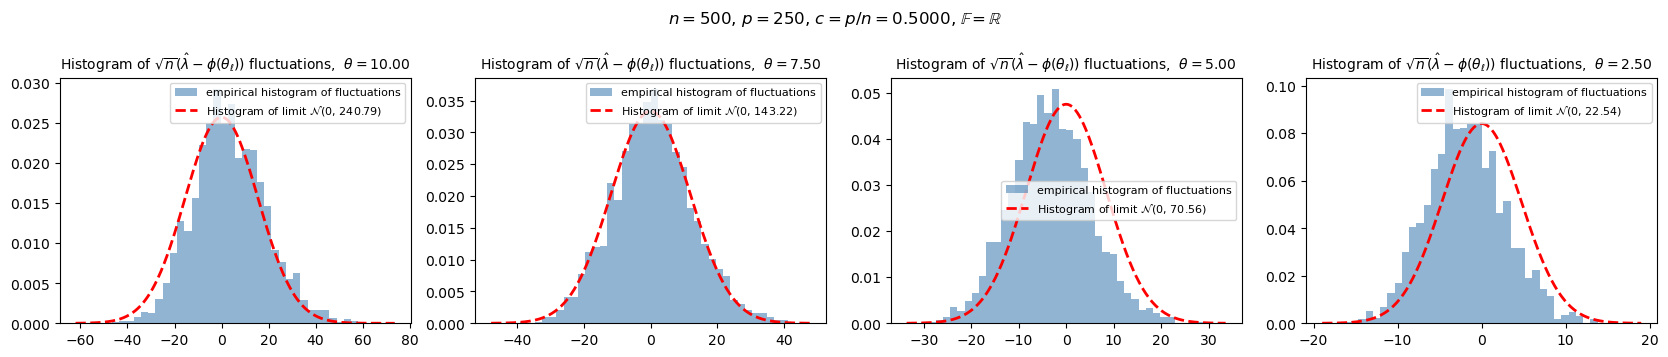

  0%|          | 0/2000 [00:00<?, ?it/s]

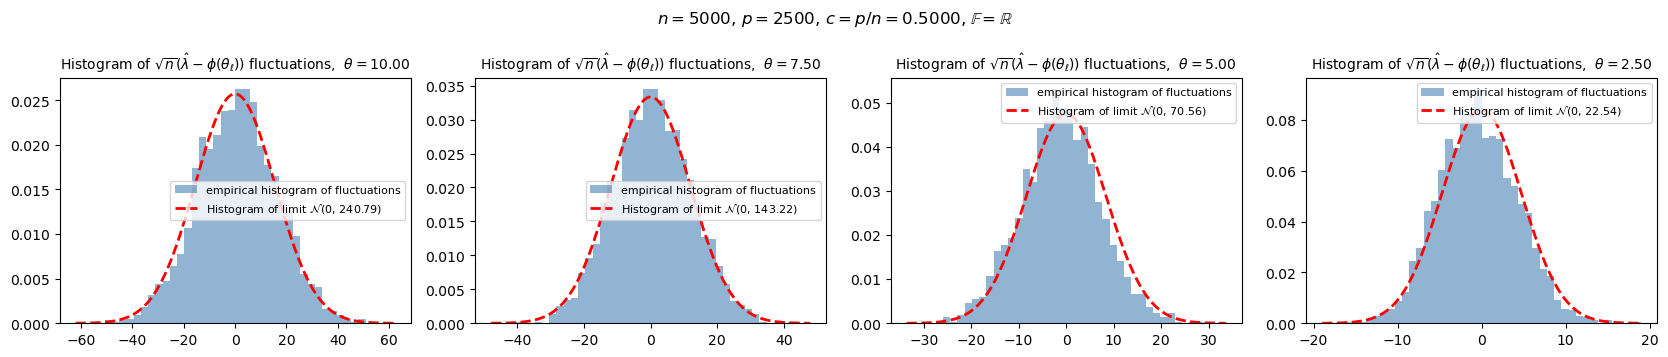

In [7]:
# Parameters for experiments 1 and 2
alphas_hist = np.array([10.0, 7.5])
betas_hist  = np.array([5.0,  2.5])

N_SIM_HIST = 2000   # number of Monte Carlo replications per (p, n)


def plot_hist_gaussian(p, n, mode, alphas, betas, sigma2, N_sim, seed=SEED):
    # Plot the empirical histogram of sqrt(n)(hat_lambda - phi(theta)) for each spike,
    # overlaid with its Gaussian limit.
    kappa = 1 if mode == 'unitary' else 2
    c = p / n

    rng = np.random.default_rng(seed)
    theta_vec, _, sample_eigs = run_haar(alphas, betas, p, n, sigma2, mode, N_sim, rng)
    K = len(theta_vec)

    fig, axes = plt.subplots(1, K, figsize=(4.2 * K, 3.6))
    for k in range(K):
        ax = axes[k]
        theta = theta_vec[k]
        fluct = np.sqrt(n) * (sample_eigs[:, k] - phi(theta, c, sigma2))

        V = V_func(theta, c, sigma2)
        std_th = np.sqrt(kappa * V) if V > 0 else None

        if std_th is not None:
            lo = min(fluct.min(), -4 * std_th)
            hi = max(fluct.max(),  4 * std_th)
        else:
            lo, hi = fluct.min(), fluct.max()
        bins = np.linspace(lo, hi, 45)

        ax.hist(fluct, bins=bins, density=True, alpha=0.6, color='steelblue',
                label='empirical histogram of fluctuations')
        if std_th is not None:
            xs = np.linspace(lo, hi, 300)
            ax.plot(xs, norm.pdf(xs, 0, std_th), 'r--', lw=2,
                    label=fr'Histogram of limit $\mathcal{{N}}(0,\,{kappa * V:.2f})$')
        ax.set_title(rf'Histogram of $\sqrt{{n}}(\hat\lambda - \phi(\theta_\ell))$ fluctuations,  '
                     rf'$\theta = {theta:.2f}$', fontsize=10)
        ax.legend(fontsize=8)

    mode_letter = r'\mathbb{C}' if mode == 'unitary' else r'\mathbb{R}'
    fig.suptitle(rf'$n = {n}$, $p = {p}$, $c = p/n = {c:.4f}$, $\mathbb{{F}} = {mode_letter}$',
                 fontsize=12)
    plt.tight_layout()
    plt.show()


# Run experiment 1
configs_exp1 = [
    (250,   500,    'orthogonal'),   # proportional regime, visible bias
    (2500,  5000,   'orthogonal'),   # same c but larger (p, n), bias decreased
    # (100,   100000, 'orthogonal'),   # sub-proportional regime, Gaussian fits poorly
]

for (p, n, mode) in configs_exp1:
    plot_hist_gaussian(p, n, mode, alphas_hist, betas_hist, sigma2, N_SIM_HIST)

## Experiment 2 — Histograms of $p(\hat\lambda_\ell - \sigma^2 - \theta_\ell)$ vs $W_\ell$

Same parameters as Experiment 1. We compare $p(\hat\lambda_\ell - \sigma^2 - \theta_\ell)$
to its theoretical limit $W_\ell$, sampled directly by Monte Carlo using its explicit
weighted-$\chi^2_1$ (resp.$Exp(1)$) representation.

We display three cases:

- $(p, n) = (100, 100000)$, real (orthogonal Haar): sub-proportional regime $p^2/n = 0.1$, good match.
- $(p, n) = (100, 100000)$, complex (unitary Haar): same regime, same kind of asymmetric one-sided $W_\ell$.
- $(p, n) = (2500, 5000)$, real: proportional regime $p^2/n = 1250$, $W_\ell$ is not the right limit.

  0%|          | 0/2000 [00:00<?, ?it/s]

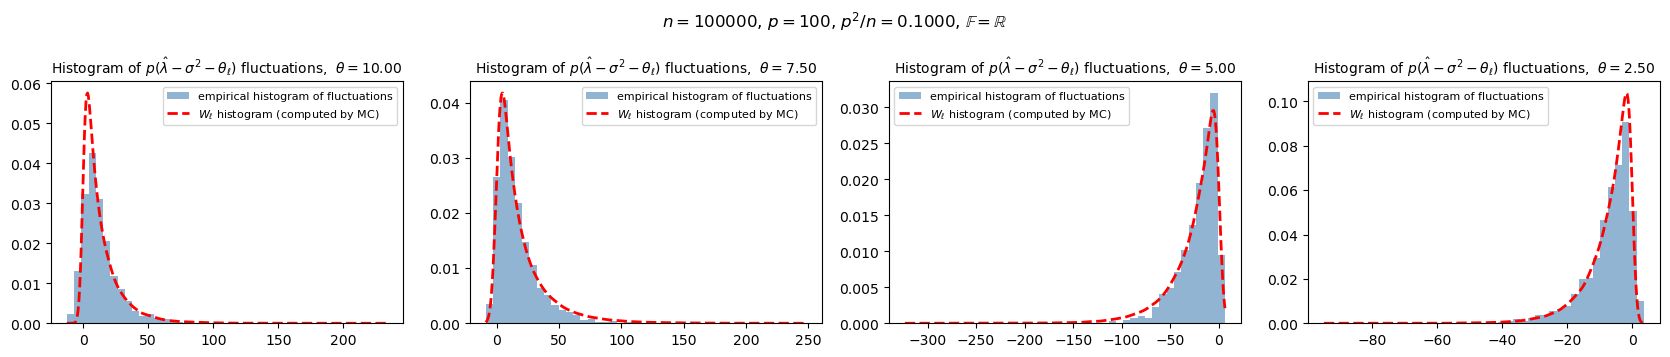

  0%|          | 0/2000 [00:00<?, ?it/s]

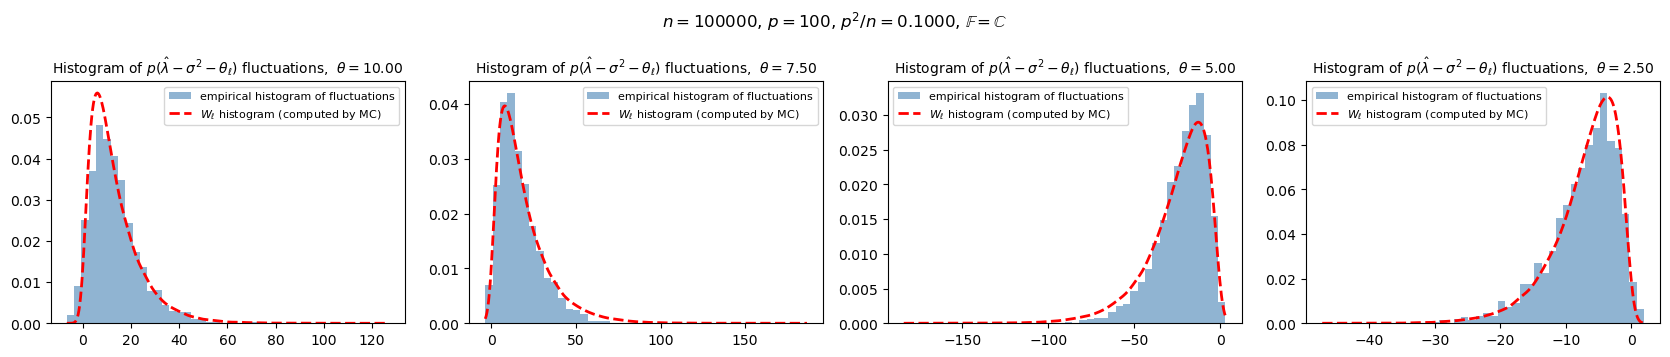

  0%|          | 0/2000 [00:00<?, ?it/s]

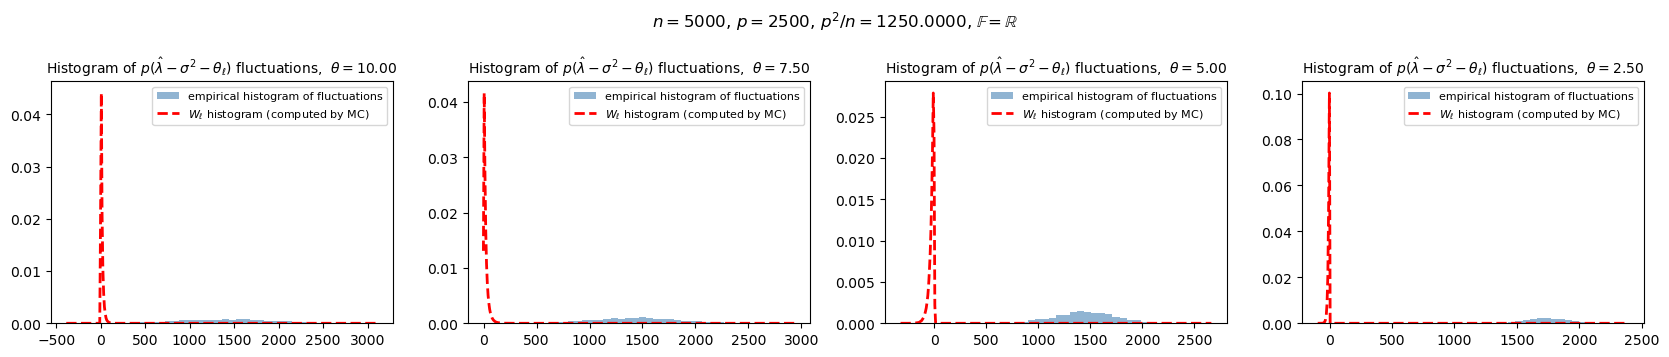

In [8]:
def plot_hist_W_ell(p, n, mode, alphas, betas, sigma2, N_sim, seed=SEED, N_MC_plot=100000):
    # Plot the empirical histogram of p(hat_lambda - sigma^2 - theta) overlaid with a KDE of W_ell.
    c = p / n
    p2_over_n = p * p / n

    rng = np.random.default_rng(seed)
    theta_vec, _, sample_eigs = run_haar(alphas, betas, p, n, sigma2, mode, N_sim, rng)
    K = len(theta_vec)

    rng_W = np.random.default_rng(seed + 999)

    fig, axes = plt.subplots(1, K, figsize=(4.2 * K, 3.6))
    for k in range(K):
        ax = axes[k]
        theta = theta_vec[k]
        fluct = p * (sample_eigs[:, k] - sigma2 - theta)
        W = sample_W_ell(theta, alphas, betas, mode, N_MC_plot, rng_W)

        lo = min(fluct.min(), W.min())
        hi = max(fluct.max(), W.max())
        bins = np.linspace(lo, hi, 45)

        ax.hist(fluct, bins=bins, density=True, alpha=0.6, color='steelblue',
                label='empirical histogram of fluctuations')

        # Smooth red dashed curve for W_ell via KDE
        kde = gaussian_kde(W, bw_method=0.15)
        xs = np.linspace(lo, hi, 400)
        ax.plot(xs, kde(xs), 'r--', lw=2,
                label=r'$W_\ell$ histogram (computed by MC)')

        ax.set_title(rf'Histogram of $p(\hat\lambda - \sigma^2 - \theta_\ell)$ fluctuations,  '
                     rf'$\theta = {theta:.2f}$', fontsize=10)
        ax.legend(fontsize=8)

    mode_letter = r'\mathbb{C}' if mode == 'unitary' else r'\mathbb{R}'
    fig.suptitle(rf'$n = {n}$, $p = {p}$, $p^2/n = {p2_over_n:.4f}$, $\mathbb{{F}} = {mode_letter}$',
                 fontsize=12)
    plt.tight_layout()
    plt.show()


# Run experiment 2
configs_exp2 = [
    (100,  100000, 'orthogonal'),   # sub-proportional, real
    (100,  100000, 'unitary'),      # sub-proportional, complex
    (2500, 5000,   'orthogonal'),   # proportional, W_ell is not the right limit
]

for (p, n, mode) in configs_exp2:
    plot_hist_W_ell(p, n, mode, alphas_hist, betas_hist, sigma2, N_SIM_HIST)

## Experiment 3 — Speed of convergence of $\sqrt{n}(\hat\lambda_\ell - \phi(\theta_\ell))$

**Setup.** New parameters: $r = s = 2$, $A = \mathrm{diag}(4.0, 2.5, \ldots)$,
$B = \mathrm{diag}(3.0, 1.5, \ldots)$, $\sigma^2 = 1$, $\mathbb{F} = \mathbb{R}$.
We track only the largest spike $\theta = 4.0$.

**Distances.** For each $(n, p)$ we run $N_{\text{sim}} = 150$ replications, compute
the empirical distribution of $\sqrt{n}(\hat\lambda_\ell - \phi(\theta_\ell))$ and
measure its distance to the Gaussian limit using:

- **Wasserstein-1**: $W_1(\mu, \nu) = \inf_\pi \mathbb{E}[|X - Y|] = \int |F_\mu - F_\nu|$ (sensitive to mean, spread, tails).
- **MMD²** with Gaussian kernel, unbiased $U$-statistic, bandwidth via median heuristic (sensitive to fine-scale local differences).

**Noise floor.** Even when the empirical distribution exactly equals the limit,
the finite sample sizes $(N_{\text{sim}}, N_{\text{MC}})$ produce non-zero distances.
We estimate this floor by drawing pairs of independent samples directly from
$\mathcal{N}(0, \kappa V)$ and averaging over $N_{\text{boot}}$ replications.
Since the Gaussian limit depends on $c = p/n$, the floor varies with $p$ and is plotted as a dotted curve.

In [9]:
# Parameters for experiments 3 and 4
alphas_dist = np.array([4.0, 2.5])
betas_dist  = np.array([3.0, 1.5])
MODE_DIST   = 'orthogonal'
KAPPA       = 1 if MODE_DIST == 'unitary' else 2

theta_vec_dist = np.sort(np.concatenate([alphas_dist, betas_dist]))[::-1]
ELL   = 0                                  # track the largest spike
THETA = float(theta_vec_dist[ELL])

N_SIM_DIST  = 150
N_MC        = 10000
N_NULL_BOOT = 30                           # number of bootstrap reps for the noise floor

# Grid for experiment 3 (edit to control runtime)
P_GRID_A   = [20, 50, 100, 200, 400, 800, 1500]
N_VALUES_A = [500, 1000, 2000]

print(f"Tracking spike #{ELL}: theta = {THETA}")
print(f"Mode = {MODE_DIST}, kappa = {KAPPA}")

Tracking spike #0: theta = 4.0
Mode = orthogonal, kappa = 2


In [10]:
# Compute distances for experiment 3
results_A = {}
for n in N_VALUES_A:
    w_list, m_list = [], []
    for p in tqdm(P_GRID_A, desc=f"  Exp 3, n={n}"):
        c = p / n
        if THETA <= sigma2 * np.sqrt(c):
            w_list.append(np.nan); m_list.append(np.nan); continue

        rng_sim = np.random.default_rng(SEED * 1000 + p * 7 + n)
        _, _, sample_eigs = run_haar(alphas_dist, betas_dist, p, n, sigma2,
                                      MODE_DIST, N_SIM_DIST, rng_sim)
        fluct = np.sqrt(n) * (sample_eigs[:, ELL] - phi(THETA, c, sigma2))

        V = V_func(THETA, c, sigma2)
        rng_lim = np.random.default_rng(SEED + 1)
        limit_x = rng_lim.standard_normal(N_MC) * np.sqrt(KAPPA * V)

        w_list.append(wasserstein1(fluct, limit_x))
        m_list.append(max(0.0, mmd_squared(fluct, limit_x)))

    results_A[n] = (np.array(P_GRID_A), np.array(w_list), np.array(m_list))
print("Done.")

  Exp 3, n=500:   0%|          | 0/7 [00:00<?, ?it/s]

  0%|          | 0/150 [00:00<?, ?it/s]

  0%|          | 0/150 [00:00<?, ?it/s]

  0%|          | 0/150 [00:00<?, ?it/s]

  0%|          | 0/150 [00:00<?, ?it/s]

  0%|          | 0/150 [00:00<?, ?it/s]

... (15 outputs left out)

  0%|          | 0/150 [00:00<?, ?it/s]

  0%|          | 0/150 [00:00<?, ?it/s]

  0%|          | 0/150 [00:00<?, ?it/s]

Done.


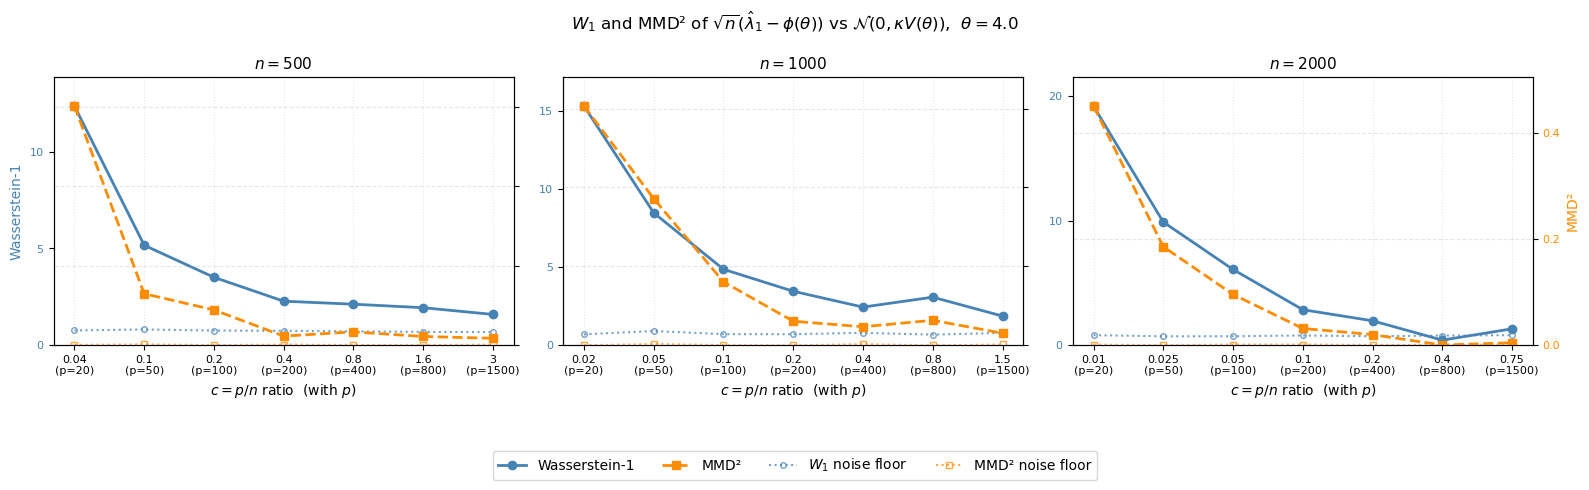

In [11]:
# Plot for experiment 3: 1 x 3 layout
def nice_locator(ax, values):
    vals = np.asarray(values, dtype=float)
    vals = vals[~np.isnan(vals)]
    if len(vals) == 0:
        return
    ax.set_ylim(bottom=0.0, top=float(np.max(vals)) * 1.12)
    ax.yaxis.set_major_locator(
        ticker.MaxNLocator(nbins=4, steps=[1, 2, 2.5, 5, 10], min_n_ticks=3)
    )


N_VALUES_A_PLOT = [500, 1000, 2000]
XLIM_A = {500: None, 1000: None, 2000: None}

fig_A, axes_A = plt.subplots(1, 3, figsize=(16, 4.5))
handles_A = None

for col, n in enumerate(N_VALUES_A_PLOT):
    ax_w = axes_A[col]
    ax_m = ax_w.twinx()

    p_arr, w_arr, m_arr = results_A[n]
    xlim = XLIM_A.get(n, None)
    if xlim is not None:
        mask = p_arr <= xlim
        p_arr_p, w_p, m_p = p_arr[mask], w_arr[mask], m_arr[mask]
    else:
        p_arr_p, w_p, m_p = p_arr, w_arr, m_arr

    # Per-p noise floor (Gaussian limit, variance changes with c = p/n)
    w_floor = np.full(len(p_arr_p), np.nan)
    m_floor = np.full(len(p_arr_p), np.nan)
    rng_null_A = np.random.default_rng(SEED + 12345 + n)
    for i, p in enumerate(p_arr_p):
        c = p / n
        V = V_func(THETA, c, sigma2)
        if V <= 0 or np.isnan(w_p[i]):
            continue
        sigma_lim = np.sqrt(KAPPA * V)
        w1s, mms = [], []
        for _ in range(N_NULL_BOOT):
            a = rng_null_A.standard_normal(N_SIM_DIST) * sigma_lim
            b = rng_null_A.standard_normal(N_MC) * sigma_lim
            w1s.append(wasserstein1(a, b))
            mms.append(mmd_squared(a, b))
        w_floor[i] = float(np.mean(w1s))
        m_floor[i] = float(np.mean(mms))

    tick_pos    = range(len(p_arr_p))
    tick_labels = [f"{p/n:.2g}\n(p={p})" for p in p_arr_p]

    l2, = ax_m.plot(tick_pos, m_p, 's--', lw=2, ms=6, color='darkorange',
                    label='MMD²')
    l1, = ax_w.plot(tick_pos, w_p, 'o-', lw=2, ms=6, color='steelblue',
                    label='Wasserstein-1')
    l4, = ax_m.plot(tick_pos, m_floor, 's:', lw=1.5, ms=4, mfc='none',
                    color='darkorange', alpha=0.75, label='MMD² noise floor')
    l3, = ax_w.plot(tick_pos, w_floor, 'o:', lw=1.5, ms=4, mfc='none',
                    color='steelblue', alpha=0.75, label='$W_1$ noise floor')

    ax_w.patch.set_visible(False)
    ax_w.set_xticks(tick_pos)
    ax_w.set_xticklabels(tick_labels, fontsize=8)
    ax_w.set_xlabel(r"$c = p/n$ ratio  (with $p$)", fontsize=10)
    ax_w.set_title(rf"$n = {n}$", fontsize=11)
    ax_w.tick_params(axis='y', labelcolor='steelblue', labelsize=8)
    ax_m.tick_params(axis='y', labelcolor='darkorange', labelsize=8)

    if col == 0:
        ax_w.set_ylabel("Wasserstein-1", fontsize=10, color='steelblue')
    if col == 2:
        ax_m.set_ylabel("MMD²", fontsize=10, color='darkorange')
    if col < 2:
        ax_m.tick_params(axis='y', labelright=False)

    nice_locator(ax_w, np.concatenate([w_p[~np.isnan(w_p)],
                                        w_floor[~np.isnan(w_floor)]]))
    nice_locator(ax_m, np.concatenate([m_p[~np.isnan(m_p)],
                                        m_floor[~np.isnan(m_floor)]]))

    ax_m.grid(True, axis='y', linestyle='--', alpha=0.3)
    ax_w.grid(True, axis='x', linestyle=':', alpha=0.3)

    if handles_A is None:
        handles_A = [l1, l2, l3, l4]

fig_A.suptitle(
    rf"$W_1$ and MMD² of $\sqrt{{n}}(\hat{{\lambda}}_{{{ELL+1}}} - \phi(\theta))$"
    rf" vs $\mathcal{{N}}(0, \kappa V(\theta))$,  $\theta = {THETA}$",
    fontsize=12
)
fig_A.legend(
    handles=handles_A,
    labels=[h.get_label() for h in handles_A],
    loc='lower center', ncol=4, fontsize=10,
    bbox_to_anchor=(0.5, -0.08)
)
plt.tight_layout(rect=[0, 0.08, 1, 1])
plt.show()

## Experiment 4 — Speed of convergence of $p(\hat\lambda_\ell - \sigma^2 - \theta_\ell)$ to $W_\ell$

Same setup as Experiment 3 (parameters $A = \mathrm{diag}(4.0, 2.5, \ldots)$,
$B = \mathrm{diag}(3.0, 1.5, \ldots)$, $\sigma^2 = 1$, $\mathbb{F} = \mathbb{R}$, $\theta = 4.0$).
We now compare $p(\hat\lambda_\ell - \sigma^2 - \theta_\ell)$ to $W_\ell$.

The grid extends to large $n$ ($n \in \{500, 1000, 2000, 10000, 50000, 100000\}$) and shows
the U-shape in $p$: for $p$ too small the limit theorem is not effective yet, for $p^2/n$ too
large the sub-proportional regime breaks down.

Since $W_\ell$ does not depend on $(p, n)$, the noise floor is a single horizontal value per $n$.

In [12]:
# Grid for experiment 4 (edit to control runtime)
P_GRID_B   = [5, 10, 20, 50, 100, 200, 500, 1000]
N_VALUES_B = [500, 1000, 2000, 10000, 50000, 100000]

# Pre-sample W_ell (does not depend on (p, n))
rng_W = np.random.default_rng(SEED + 999)
W_samples = sample_W_ell(THETA, alphas_dist, betas_dist, MODE_DIST, N_MC, rng_W)
print(f"W_ell stats: mean = {W_samples.mean():+.3f},  std = {W_samples.std():.3f}")

W_ell stats: mean = +14.549,  std = 17.629


In [13]:
# Compute distances for experiment 4
results_B = {}
for n in N_VALUES_B:
    w_list, m_list = [], []
    for p in tqdm(P_GRID_B, desc=f"  Exp 4, n={n}"):
        rng_sim = np.random.default_rng(SEED * 100 + p * 13 + n + 5)
        _, _, sample_eigs = run_haar(alphas_dist, betas_dist, p, n, sigma2,
                                      MODE_DIST, N_SIM_DIST, rng_sim)
        fluct = p * (sample_eigs[:, ELL] - sigma2 - THETA)
        w_list.append(wasserstein1(fluct, W_samples))
        m_list.append(max(0.0, mmd_squared(fluct, W_samples)))

    results_B[n] = (np.array(P_GRID_B), np.array(w_list), np.array(m_list))
print("Done.")

  Exp 4, n=500:   0%|          | 0/8 [00:00<?, ?it/s]

  0%|          | 0/150 [00:00<?, ?it/s]

  0%|          | 0/150 [00:00<?, ?it/s]

  0%|          | 0/150 [00:00<?, ?it/s]

  0%|          | 0/150 [00:00<?, ?it/s]

  0%|          | 0/150 [00:00<?, ?it/s]

... (45 outputs left out)

  0%|          | 0/150 [00:00<?, ?it/s]

  0%|          | 0/150 [00:00<?, ?it/s]

  0%|          | 0/150 [00:00<?, ?it/s]

Done.


In [14]:
# Noise floor for experiment 4 (W_ell, fixed for all p)
rng_null_B = np.random.default_rng(SEED + 31415)
w1_floor_vals, mmd_floor_vals = [], []
for _ in range(N_NULL_BOOT):
    a = sample_W_ell(THETA, alphas_dist, betas_dist, MODE_DIST, N_SIM_DIST, rng_null_B)
    b = sample_W_ell(THETA, alphas_dist, betas_dist, MODE_DIST, N_MC, rng_null_B)
    w1_floor_vals.append(wasserstein1(a, b))
    mmd_floor_vals.append(mmd_squared(a, b))
w1_floor_B  = float(np.mean(w1_floor_vals))
mmd_floor_B = float(np.mean(mmd_floor_vals))
print(f"Noise floor:  W1 = {w1_floor_B:.4f},  MMD² = {mmd_floor_B:.6f}")

Noise floor:  W1 = 1.8311,  MMD² = 0.000362


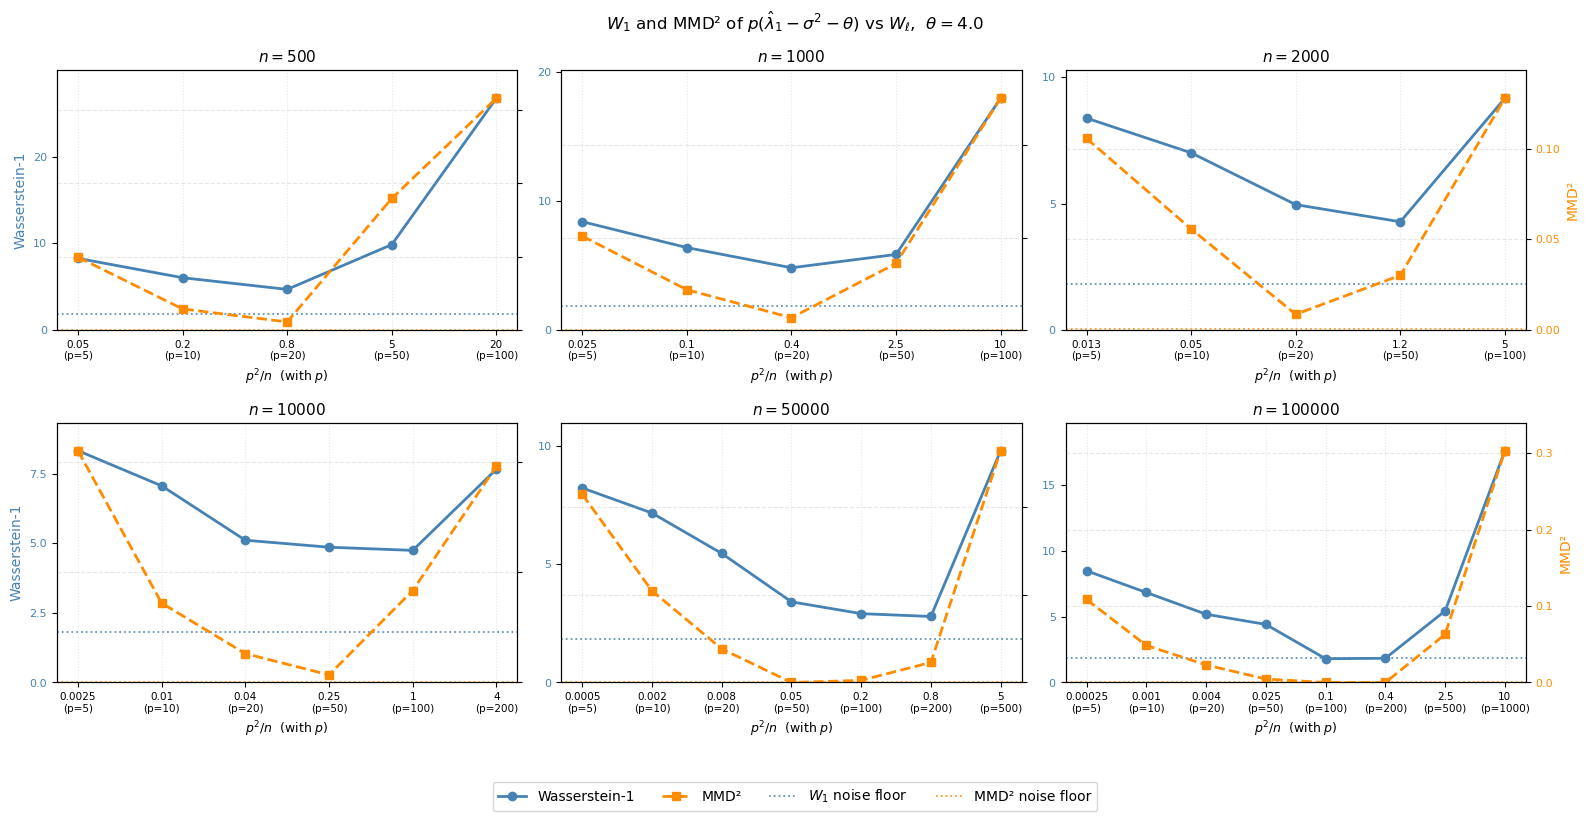

In [15]:
# Plot for experiment 4: 2 x 3 layout
N_VALUES_B_PLOT = [500, 1000, 2000, 10000, 50000, 100000]

# Per-n cap on p^2/n (set to None to show all points)
XLIM_RATIO_B = {
    500:    20,
    1000:   10,
    2000:   5,
    10000:  4,
    50000:  5,
    100000: None,
}

fig_B, axes_B = plt.subplots(2, 3, figsize=(16, 8))
handles_B = None

for idx, n in enumerate(N_VALUES_B_PLOT):
    row, col = divmod(idx, 3)
    ax_w = axes_B[row, col]
    ax_m = ax_w.twinx()

    p_arr, w_arr, m_arr = results_B[n]
    ratio_arr = p_arr ** 2 / n

    xlim = XLIM_RATIO_B.get(n, None)
    if xlim is not None:
        mask = ratio_arr <= xlim
        p_arr_p, ratio_p, w_p, m_p = (p_arr[mask], ratio_arr[mask],
                                       w_arr[mask], m_arr[mask])
    else:
        p_arr_p, ratio_p, w_p, m_p = p_arr, ratio_arr, w_arr, m_arr

    tick_pos    = range(len(p_arr_p))
    tick_labels = [f"{r:.2g}\n(p={p})" for r, p in zip(ratio_p, p_arr_p)]

    l2, = ax_m.plot(tick_pos, m_p, 's--', lw=2, ms=6, color='darkorange',
                    label='MMD²')
    l1, = ax_w.plot(tick_pos, w_p, 'o-', lw=2, ms=6, color='steelblue',
                    label='Wasserstein-1')
    l3 = ax_w.axhline(w1_floor_B, color='steelblue', lw=1.3, ls=':', alpha=0.85,
                      label='$W_1$ noise floor')
    l4 = ax_m.axhline(mmd_floor_B, color='darkorange', lw=1.3, ls=':', alpha=0.85,
                      label='MMD² noise floor')

    ax_w.patch.set_visible(False)
    ax_w.set_xticks(tick_pos)
    ax_w.set_xticklabels(tick_labels, fontsize=7.5)
    ax_w.set_xlabel(r"$p^2/n$  (with $p$)", fontsize=9)
    ax_w.set_title(rf"$n = {n}$", fontsize=11)
    ax_w.tick_params(axis='y', labelcolor='steelblue', labelsize=8)
    ax_m.tick_params(axis='y', labelcolor='darkorange', labelsize=8)

    if col == 0:
        ax_w.set_ylabel("Wasserstein-1", fontsize=10, color='steelblue')
    if col == 2:
        ax_m.set_ylabel("MMD²", fontsize=10, color='darkorange')
    if col < 2:
        ax_m.tick_params(axis='y', labelright=False)

    nice_locator(ax_w, np.append(w_p, w1_floor_B))
    nice_locator(ax_m, np.append(m_p, mmd_floor_B))

    ax_m.grid(True, axis='y', linestyle='--', alpha=0.3)
    ax_w.grid(True, axis='x', linestyle=':', alpha=0.3)

    if handles_B is None:
        handles_B = [l1, l2, l3, l4]

fig_B.suptitle(
    rf"$W_1$ and MMD² of $p(\hat{{\lambda}}_{{{ELL+1}}} - \sigma^2 - \theta)$"
    rf" vs $W_\ell$,  $\theta = {THETA}$",
    fontsize=12
)
fig_B.legend(
    handles=handles_B,
    labels=[h.get_label() for h in handles_B],
    loc='lower center', ncol=4, fontsize=10,
    bbox_to_anchor=(0.5, -0.03)
)
plt.tight_layout(rect=[0, 0.05, 1, 1])
plt.show()

## Additional experiments — boundary and sample-dominated regimes

So far we have tested two regimes: the proportional regime ($p/n \to c \in (0, \infty)$, Bai–Yao Gaussian limit) and the sub-proportional regime ($p^2/n \to 0$, limit $W_\ell$). We now test two intermediate / extreme regimes:

- Boundary regime ($p/n \to 0$, $p^2/n \to \tau \in (0, \infty)$). The limit is a sum of three terms: the sub-proportional contribution $W_\ell$, a Gaussian noise of variance $\kappa\tau(\sigma^2+\theta_\ell)^2$, and a deterministic drift $\tau \, \sigma^2(\sigma^2+\theta_\ell)/\theta_\ell$.
- Sample-dominated sub-proportional regime ($p/n \to 0$, $p^2/n \to \infty$). The $W_\ell$ contribution disappears, only the Gaussian noise and a properly centered drift remain.

These two regimes interpolate between sub-proportional ($\tau \to 0$, recovers $W_\ell$) and the proportional Bai–Yao limit ($\tau \to \infty$, recovers a pure Gaussian).

We keep the parameters of experiments 1 and 2: $\alpha = (10, 7.5)$, $\beta = (5, 2.5)$, $\sigma^2 = 1$, $\mathbb{F} = \mathbb{R}$.

### Boundary regime

We test:
$$
p(\hat\lambda_\ell - \sigma^2 - \theta_\ell) \xrightarrow{\text{law}} W_\ell + \sqrt{\kappa\tau}\,(\sigma^2 + \theta_\ell)\,G_\ell + \tau \frac{\sigma^2(\sigma^2 + \theta_\ell)}{\theta_\ell},
$$
where $G_\ell \sim \mathcal{N}(0, 1)$ is independent of $W_\ell$, and we set $\tau = p^2/n$ from the finite $(p, n)$.

We compare the empirical histogram of $p(\hat\lambda_\ell - \sigma^2 - \theta_\ell)$ to a Monte Carlo sample of the boundary limit (a sum of three independent contributions: $W_\ell$ from `sample_W_ell`, a Gaussian, and a constant).

We pick three $(p, n)$ with different $\tau$:
- $(p, n) = (100, 20000)$: $\tau = 0.5$, close to sub-proportional. Shape should look like $W_\ell$ with a small Gaussian smoothing and a small drift.
- $(p, n) = (200, 20000)$: $\tau = 2$, intermediate. Mix of $W_\ell$ shape and Gaussian.
- $(p, n) = (300, 9000)$: $\tau = 10$, close to sample-dominated. Gaussian should dominate, drift becomes substantial.

  0%|          | 0/2000 [00:00<?, ?it/s]

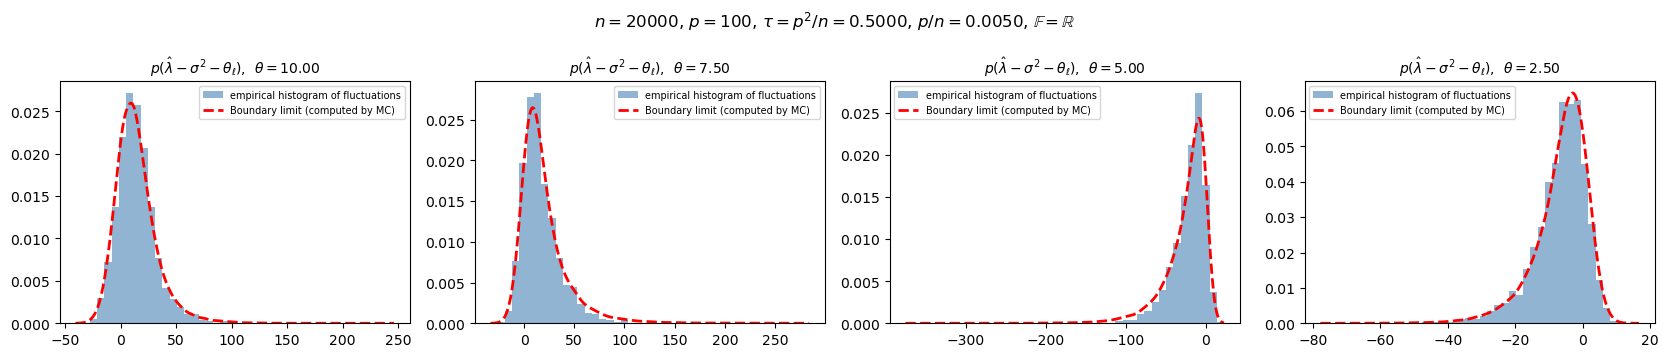

  0%|          | 0/2000 [00:00<?, ?it/s]

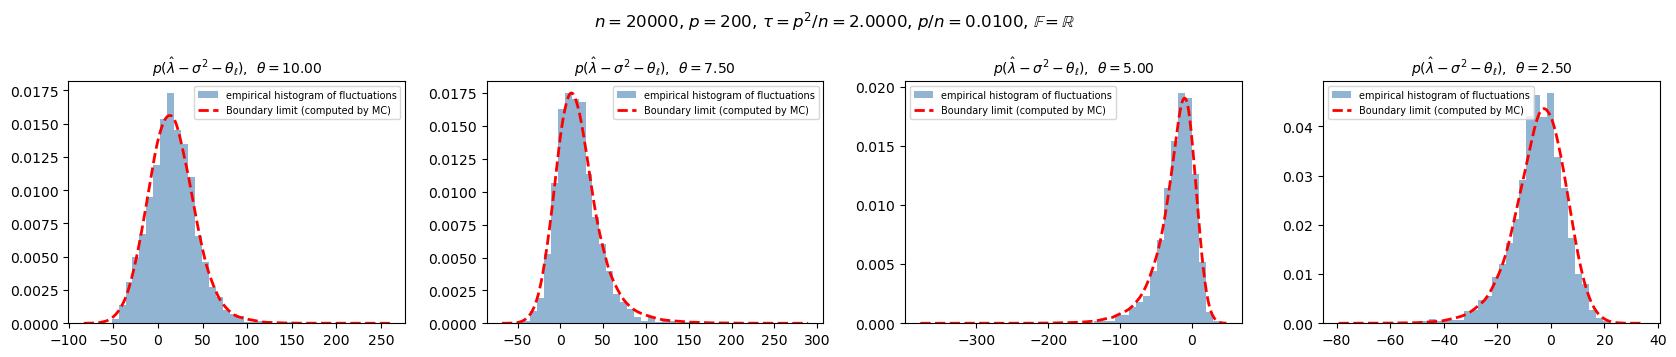

  0%|          | 0/2000 [00:00<?, ?it/s]

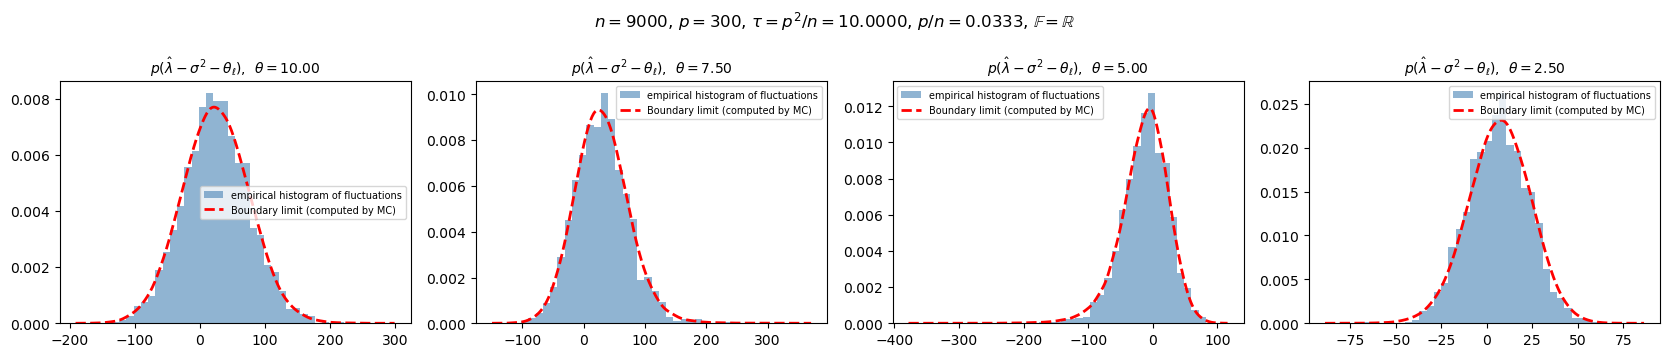

In [22]:
N_SIM_NEW = 2000   # reduce if too slow


def boundary_limit_samples(theta, alphas, betas, mode, p, n, sigma2, N_mc, rng):
    """
    Monte Carlo sample of the boundary limit:
       W_ell + sqrt(kappa * tau) * (sigma^2 + theta) * G + tau * sigma^2 * (sigma^2 + theta) / theta
    where tau = p^2 / n and G ~ N(0, 1) is independent of W_ell.
    """
    kappa = 1 if mode == 'unitary' else 2
    tau = p * p / n
    W = sample_W_ell(theta, alphas, betas, mode, N_mc, rng)
    G = rng.standard_normal(N_mc)
    drift = tau * sigma2 * (sigma2 + theta) / theta
    gauss = np.sqrt(kappa * tau) * (sigma2 + theta) * G
    return W + gauss + drift


def plot_hist_boundary(p, n, mode, alphas, betas, sigma2, N_sim, seed=SEED, N_MC_plot=100000):
    """Empirical histogram of p*(hat_lambda - sigma^2 - theta) vs boundary limit (KDE)."""
    c = p / n
    tau = p * p / n

    rng = np.random.default_rng(seed)
    theta_vec, _, sample_eigs = run_haar(alphas, betas, p, n, sigma2, mode, N_sim, rng)
    K = len(theta_vec)

    rng_W = np.random.default_rng(seed + 999)

    fig, axes = plt.subplots(1, K, figsize=(4.2 * K, 3.6))
    for k in range(K):
        ax = axes[k]
        theta = theta_vec[k]
        fluct = p * (sample_eigs[:, k] - sigma2 - theta)
        limit = boundary_limit_samples(theta, alphas, betas, mode, p, n, sigma2, N_MC_plot, rng_W)

        lo = min(fluct.min(), limit.min())
        hi = max(fluct.max(), limit.max())
        bins = np.linspace(lo, hi, 45)

        ax.hist(fluct, bins=bins, density=True, alpha=0.6, color='steelblue',
                label='empirical histogram of fluctuations')
        kde = gaussian_kde(limit, bw_method=0.15)
        xs = np.linspace(lo, hi, 400)
        ax.plot(xs, kde(xs), 'r--', lw=2,
                label='Boundary limit (computed by MC)')

        ax.set_title(rf'$p(\hat\lambda - \sigma^2 - \theta_\ell)$,  $\theta = {theta:.2f}$',
                     fontsize=10)
        ax.legend(fontsize=7)

    mode_letter = r'\mathbb{C}' if mode == 'unitary' else r'\mathbb{R}'
    fig.suptitle(rf'$n = {n}$, $p = {p}$, $\tau = p^2/n = {tau:.4f}$, '
                 rf'$p/n = {c:.4f}$, $\mathbb{{F}} = {mode_letter}$', fontsize=12)
    plt.tight_layout()
    plt.show()


# Run the boundary regime experiment
configs_boundary = [
    (100, 20000, 'orthogonal'),   # tau = 0.5
    (200, 20000, 'orthogonal'),   # tau = 2
    (300, 9000,  'orthogonal'),   # tau = 10
]

for (p, n, mode) in configs_boundary:
    plot_hist_boundary(p, n, mode, alphas_hist, betas_hist, sigma2, N_SIM_NEW)

### Sample-dominated sub-proportional regime

We test:
$$
\sqrt{n}\left(\hat\lambda_\ell - \sigma^2 - \theta_\ell - \frac{p}{n}\frac{\sigma^2(\sigma^2 + \theta_\ell)}{\theta_\ell}\right) \xrightarrow{\text{law}} \sqrt{\kappa}(\sigma^2 + \theta_\ell)\, G_\ell,
$$
 as $p/n \to 0$, $p^2/n \to \infty$, with $G_\ell \sim \mathcal{N}(0, 1)$. The drift $(p/n)\sigma^2(\sigma^2 + \theta_\ell)/\theta_\ell$ must be subtracted before scaling by $\sqrt{n}$; otherwise the empirical mean does not converge to $0$.

We compare the empirical histogram of the corrected fluctuation to $\mathcal{N}(0, \kappa(\sigma^2 + \theta_\ell)^2)$. We test two $(p, n)$ pairs with $p^2/n$ large and $p/n$ small:

- $(p, n) = (200, 2000)$: $p^2/n = 20$, $p/n = 0.10$.
- $(p, n) = (500, 5000)$: $p^2/n = 250$, $p/n = 0.1$.


In [38]:
1000*1000/20000

50.0

In [39]:
1000/20000

0.05

  0%|          | 0/2000 [00:00<?, ?it/s]

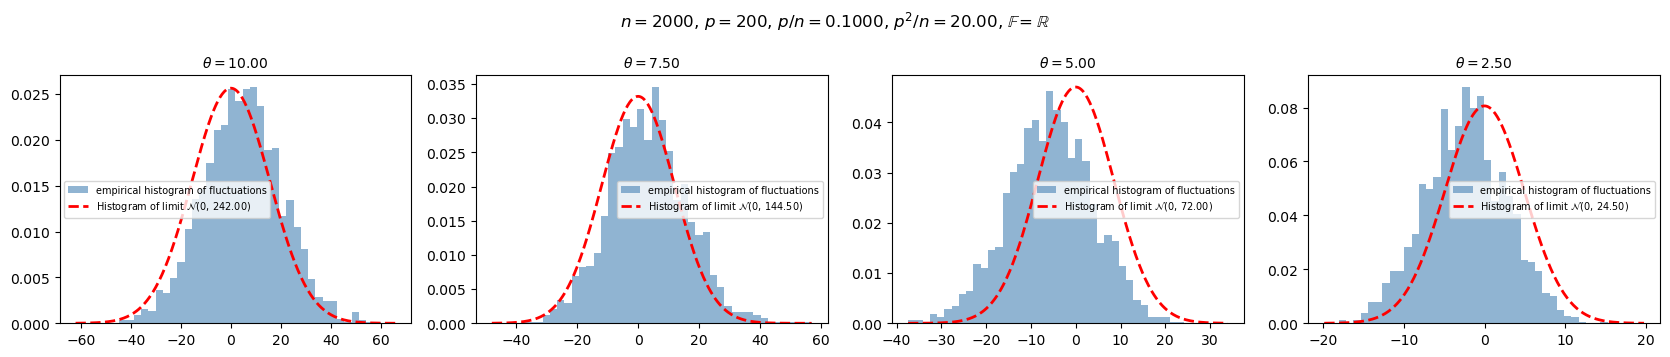

  0%|          | 0/2000 [00:00<?, ?it/s]

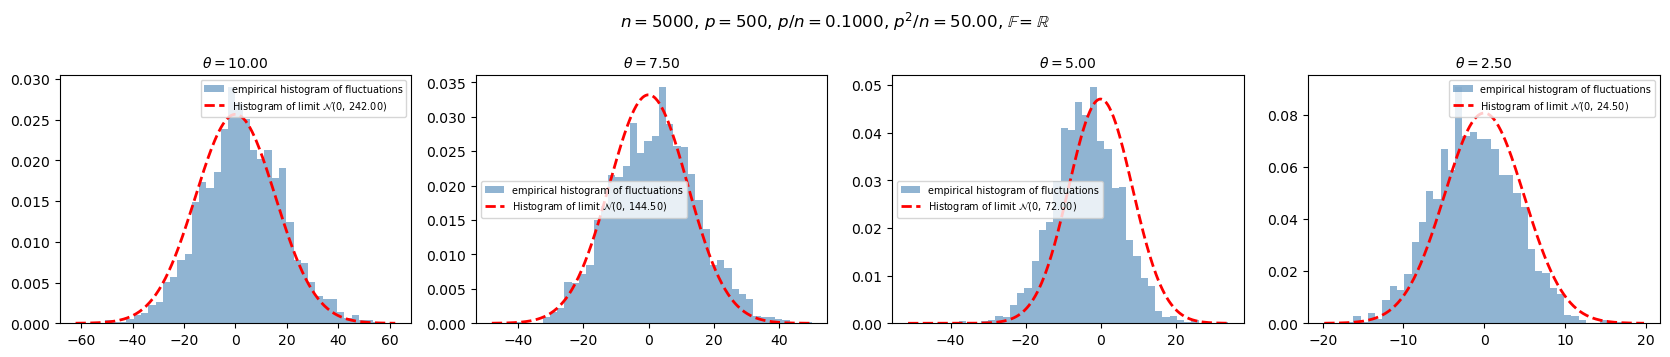

In [28]:
def plot_hist_sample_dominated(p, n, mode, alphas, betas, sigma2, N_sim, seed=SEED):
    """
    Empirical histogram of
        sqrt(n) * (hat_lambda - sigma^2 - theta - (p/n) * sigma^2 * (sigma^2 + theta) / theta)
    vs N(0, kappa * (sigma^2 + theta)^2).
    """
    kappa = 1 if mode == 'unitary' else 2
    c = p / n
    tau = p * p / n

    rng = np.random.default_rng(seed)
    theta_vec, _, sample_eigs = run_haar(alphas, betas, p, n, sigma2, mode, N_sim, rng)
    K = len(theta_vec)

    fig, axes = plt.subplots(1, K, figsize=(4.2 * K, 3.6))
    for k in range(K):
        ax = axes[k]
        theta = theta_vec[k]
        correction = (p / n) * sigma2 * (sigma2 + theta) / theta
        fluct = np.sqrt(n) * (sample_eigs[:, k] - sigma2 - theta - correction)

        std_th = np.sqrt(kappa) * (sigma2 + theta)
        var_th = kappa * (sigma2 + theta) ** 2

        lo = min(fluct.min(), -4 * std_th)
        hi = max(fluct.max(),  4 * std_th)
        bins = np.linspace(lo, hi, 45)

        ax.hist(fluct, bins=bins, density=True, alpha=0.6, color='steelblue',
                label='empirical histogram of fluctuations')
        xs = np.linspace(lo, hi, 300)
        ax.plot(xs, norm.pdf(xs, 0, std_th), 'r--', lw=2,
                label=fr'Histogram of limit $\mathcal{{N}}(0,\,{var_th:.2f})$')

        ax.set_title(rf'$\theta = {theta:.2f}$', fontsize=10)
        ax.legend(fontsize=7)

    mode_letter = r'\mathbb{C}' if mode == 'unitary' else r'\mathbb{R}'
    fig.suptitle(rf'$n = {n}$, $p = {p}$, $p/n = {c:.4f}$, $p^2/n = {tau:.2f}$, '
                 rf'$\mathbb{{F}} = {mode_letter}$', fontsize=12)
    plt.tight_layout()
    plt.show()


# Run the sample-dominated experiment
configs_sd = [
    (200, 2000, 'orthogonal'),    # p²/n = 20, p/n = 0.10
    (500, 5000, 'orthogonal'),    # p²/n = 250, p/n = 0.1
]

for (p, n, mode) in configs_sd:
    plot_hist_sample_dominated(p, n, mode, alphas_hist, betas_hist, sigma2, N_SIM_NEW)

  0%|          | 0/2000 [00:00<?, ?it/s]

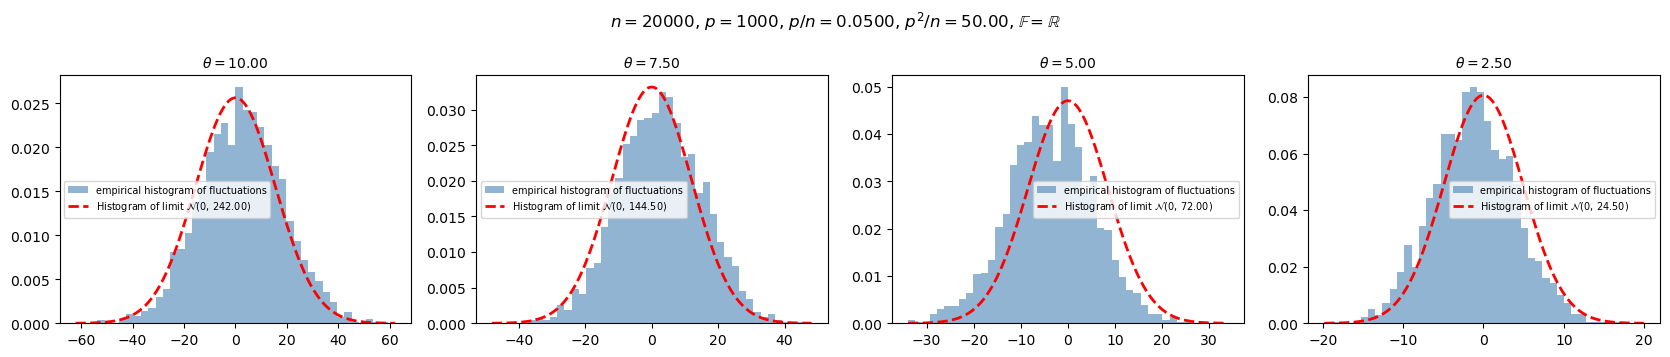

In [40]:
configs_sd = [
    (1000, 20000, 'orthogonal')   # p²/n = 250, p/n = 0.1
]

for (p, n, mode) in configs_sd:
    plot_hist_sample_dominated(p, n, mode, alphas_hist, betas_hist, sigma2, N_SIM_NEW)

## Appendix — finite-$n$ bias analysis

The histograms of Experiment 1 reveal a small but visible bias of the empirical fluctuation
of $\sqrt{n}(\hat\lambda_\ell - \phi(\theta_\ell))$ at finite $n$. The four experiments below
isolate the mechanisms behind this bias.

All experiments use $\sigma^2 = 1$ and average over $N_{\text{sim}} = 2000$ replications.

- **Appendix Exp.\ 1**: deterministic spiked model vs Haar spiked model, same $(p, n)$ and same spikes. Shows that the bias is also present without any Haar randomness, and that the Haar randomness only adds an extra contribution on top.
- **Appendix Exp.\ 2**: bias vs $n$ at fixed $c = p/n$ in the deterministic model. Shows the bias decreases with $n$.
- **Appendix Exp.\ 3**: a single isolated spike $\theta = 2.5$ vs the same spike placed inside the group $\{10, 7.5, 5, 2.5\}$. Shows that the bias is essentially an interaction between spikes.
- **Appendix Exp.\ 4**: in the Haar model, bias evolution as $p$ grows at fixed $n$. Shows that as $p$ grows the Haar drift vanishes and the Wishart bias dominates.

In [16]:
# Common appendix parameters
alphas_app    = np.array([10.0, 7.5])
betas_app     = np.array([5.0,  2.5])
theta_vec_app = np.sort(np.concatenate([alphas_app, betas_app]))[::-1]   # [10, 7.5, 5, 2.5]
K_app         = len(theta_vec_app)
N_SIM_APP     = 2000
kappa_app     = 2   # real / orthogonal

### Appendix Exp.\ 1 — deterministic spiked model vs Haar spiked model

Both models with the same spike values $\{10, 7.5, 5, 2.5\}$, same $(p, n) = (200, 400)$.
We plot $\sqrt{n}(\hat\lambda_\ell - \phi(\theta_\ell))$ in both cases and overlay the Gaussian
limit $\mathcal{N}(0, \kappa V(\theta_\ell))$. The green dotted vertical line is the empirical mean.

  0%|          | 0/2000 [00:00<?, ?it/s]


 theta    det bias   haar bias    det std   haar std   theo std
--------------------------------------------------------------
  10.0       +2.73       +3.99      15.07      15.28      15.52
   7.5       -0.78       +1.04      11.44      11.64      11.97
   5.0       -1.56       -3.45       8.31       8.38       8.40
   2.5       -1.19       -1.73       4.61       4.64       4.75


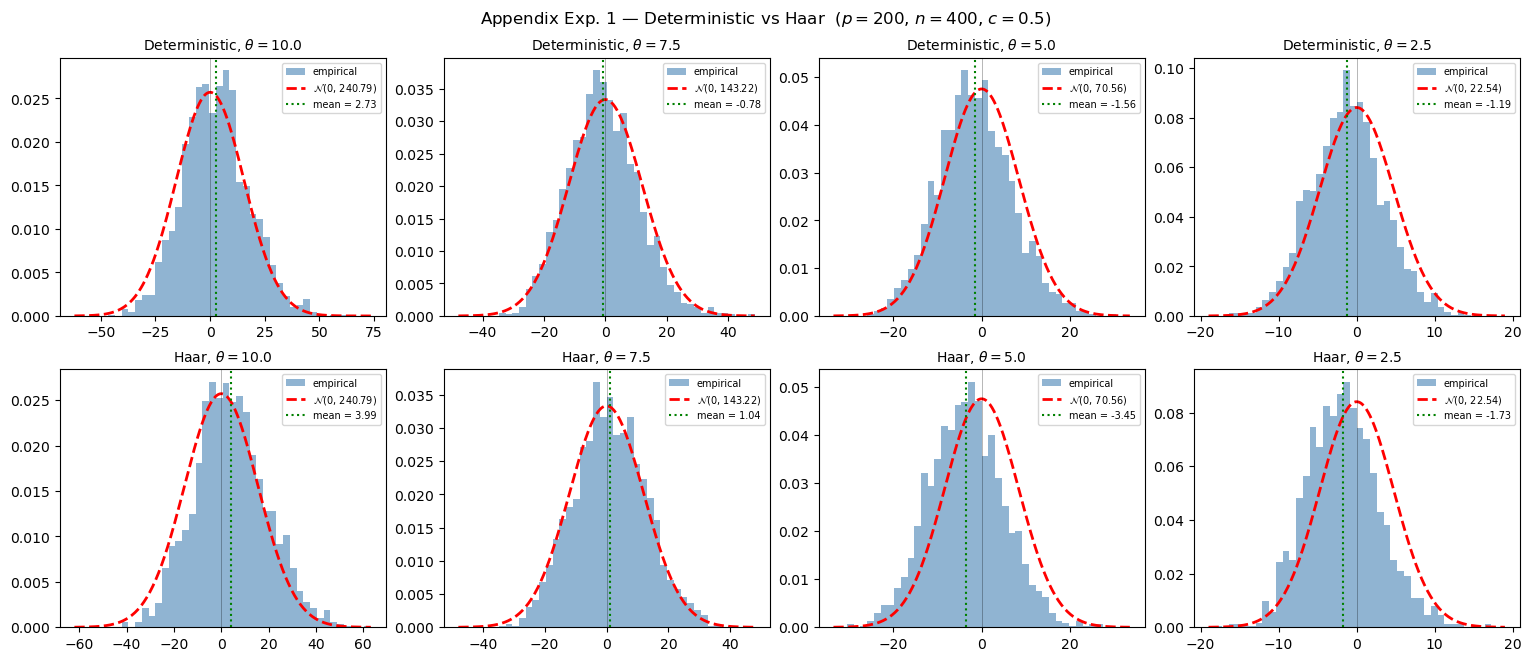

In [17]:
# Appendix Exp 1
p, n = 200, 400
c = p / n

# Deterministic model
rng = np.random.default_rng(SEED)
det_spikes, det_eigs = run_deterministic(theta_vec_app, p, n, sigma2, N_SIM_APP, rng)
det_fluct = np.sqrt(n) * (det_eigs - phi(det_spikes, c, sigma2))

# Haar model
rng = np.random.default_rng(SEED)
_, _, haar_eigs = run_haar(alphas_app, betas_app, p, n, sigma2, 'orthogonal', N_SIM_APP, rng)
haar_fluct = np.sqrt(n) * (haar_eigs - phi(theta_vec_app, c, sigma2))

print(f"\n{'theta':>6s}  {'det bias':>10s}  {'haar bias':>10s}  "
      f"{'det std':>9s}  {'haar std':>9s}  {'theo std':>9s}")
print("-" * 62)
for k in range(K_app):
    th = theta_vec_app[k]
    theo_std = np.sqrt(kappa_app * V_func(th, c, sigma2))
    print(f"{th:6.1f}  {det_fluct[:, k].mean():+10.2f}  {haar_fluct[:, k].mean():+10.2f}  "
          f"{det_fluct[:, k].std():9.2f}  {haar_fluct[:, k].std():9.2f}  {theo_std:9.2f}")

# Plot: 2 rows (det then Haar) x K_app columns
fig, axes = plt.subplots(2, K_app, figsize=(3.8 * K_app, 6.5), constrained_layout=True)
for k in range(K_app):
    th = theta_vec_app[k]
    V_val = V_func(th, c, sigma2)
    std_th = np.sqrt(kappa_app * V_val) if V_val > 0 else None
    for row, data, label in [(0, det_fluct[:, k], 'Deterministic'),
                              (1, haar_fluct[:, k], 'Haar')]:
        ax = axes[row, k]
        if std_th is not None:
            lo = min(data.min(), -4 * std_th)
            hi = max(data.max(),  4 * std_th)
        else:
            lo, hi = data.min(), data.max()
        bins = np.linspace(lo, hi, 45)
        ax.hist(data, bins=bins, density=True, alpha=0.6, color='steelblue', label='empirical')
        if std_th is not None:
            xs = np.linspace(lo, hi, 300)
            ax.plot(xs, norm.pdf(xs, 0, std_th), 'r--', lw=2,
                    label=fr'$\mathcal{{N}}(0,\,{kappa_app * V_val:.2f})$')
        ax.axvline(0, color='k', lw=0.5, alpha=0.4)
        ax.axvline(data.mean(), color='green', lw=1.5, ls=':',
                   label=f'mean = {data.mean():.2f}')
        ax.set_title(rf'{label}, $\theta = {th:.1f}$', fontsize=10)
        ax.legend(fontsize=7)

fig.suptitle(rf'Appendix Exp. 1 — Deterministic vs Haar  ($p = {p}$, $n = {n}$, $c = {c}$)',
             fontsize=12)
plt.show()

### Appendix Exp.\ 2 — bias vs $n$ at fixed $c = 0.5$ (deterministic model)

Same spikes $\{10, 7.5, 5, 2.5\}$. We let $(p, n)$ grow with $c = p/n = 0.5$ fixed.
We report the empirical mean of $\sqrt{n}(\hat\lambda_\ell - \phi(\theta_\ell))$ in a table.

In [18]:
# Appendix Exp 2
configs_n = [(200, 400), (400, 800), (800, 1600)]
bias_table_2 = {}

for (p_, n_) in configs_n:
    rng_ = np.random.default_rng(SEED)
    _, eigs_ = run_deterministic(theta_vec_app, p_, n_, sigma2, N_SIM_APP, rng_)
    fluct_ = np.sqrt(n_) * (eigs_ - phi(theta_vec_app, p_ / n_, sigma2))
    bias_table_2[n_] = fluct_.mean(0)

print(f"\n{'n':>6s}", end="")
for th in theta_vec_app:
    print(f"  {f'theta={th:g}':>12s}", end="")
print()
print("-" * (10 + 14 * K_app))
for n_ in sorted(bias_table_2):
    print(f"{n_:6d}", end="")
    for val in bias_table_2[n_]:
        print(f"  {val:+12.2f}", end="")
    print()


     n      theta=10     theta=7.5       theta=5     theta=2.5
------------------------------------------------------------------
   400         +2.73         -0.78         -1.56         -1.19
   800         +1.48         -0.59         -0.78         -0.82
  1600         +1.03         -0.16         -0.56         -0.71


### Appendix Exp.\ 3 — single spike alone vs spike inside a group (deterministic model)

We track $\theta = 2.5$ in two situations:

- alone (only spike of the model),
- inside the group $\{10, 7.5, 5, 2.5\}$.

We compare $\sqrt{n}(\hat\lambda_\ell - \phi(\theta_\ell))$ in both cases to its Gaussian limit.


  theta = 2.5 alone : bias = -0.02,  std = 4.74
  theta = 2.5 in grp: bias = -1.19,  std = 4.61
  theoretical std    : 4.75


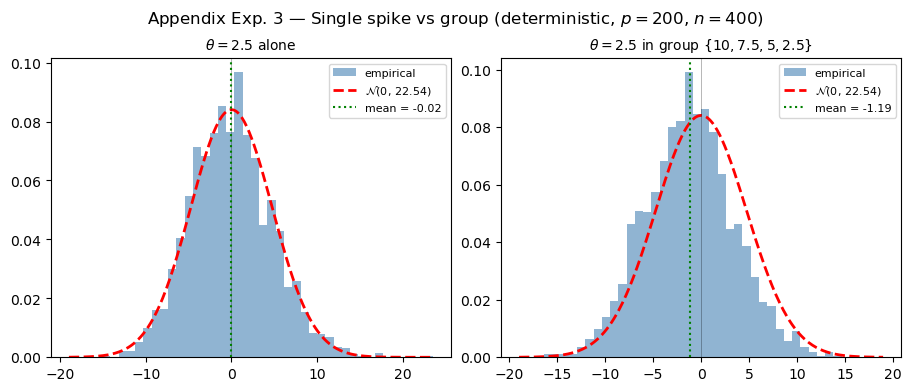

In [19]:
# Appendix Exp 3
p, n = 200, 400
c = p / n
THETA_ISOLATED = 2.5

# Alone
rng3a = np.random.default_rng(SEED)
_, eigs_alone = run_deterministic([THETA_ISOLATED], p, n, sigma2, N_SIM_APP, rng3a)
fluct_alone = np.sqrt(n) * (eigs_alone[:, 0] - phi(THETA_ISOLATED, c, sigma2))

# Inside the group
rng3b = np.random.default_rng(SEED)
sp3, eigs_group = run_deterministic(theta_vec_app, p, n, sigma2, N_SIM_APP, rng3b)
idx_in_group = int(np.argmin(np.abs(sp3 - THETA_ISOLATED)))
fluct_group = np.sqrt(n) * (eigs_group[:, idx_in_group] - phi(THETA_ISOLATED, c, sigma2))

print(f"\n  theta = {THETA_ISOLATED} alone : bias = {fluct_alone.mean():+.2f},  "
      f"std = {fluct_alone.std():.2f}")
print(f"  theta = {THETA_ISOLATED} in grp: bias = {fluct_group.mean():+.2f},  "
      f"std = {fluct_group.std():.2f}")
print(f"  theoretical std    : {np.sqrt(kappa_app * V_func(THETA_ISOLATED, c, sigma2)):.2f}")

# Plot
fig3, (ax3a, ax3b) = plt.subplots(1, 2, figsize=(9, 3.8), constrained_layout=True)
std_iso = np.sqrt(kappa_app * V_func(THETA_ISOLATED, c, sigma2))

for ax, data, title in [(ax3a, fluct_alone, rf'$\theta = {THETA_ISOLATED}$ alone'),
                         (ax3b, fluct_group,
                          rf'$\theta = {THETA_ISOLATED}$ in group $\{{10, 7.5, 5, 2.5\}}$')]:
    lo = min(data.min(), -4 * std_iso)
    hi = max(data.max(),  4 * std_iso)
    bins = np.linspace(lo, hi, 45)
    ax.hist(data, bins=bins, density=True, alpha=0.6, color='steelblue', label='empirical')
    xs = np.linspace(lo, hi, 300)
    ax.plot(xs, norm.pdf(xs, 0, std_iso), 'r--', lw=2,
            label=fr'$\mathcal{{N}}(0,\,{kappa_app * V_func(THETA_ISOLATED, c):.2f})$')
    ax.axvline(0, color='k', lw=0.5, alpha=0.4)
    ax.axvline(data.mean(), color='green', lw=1.5, ls=':',
               label=f'mean = {data.mean():.2f}')
    ax.set_title(title, fontsize=10)
    ax.legend(fontsize=8)

fig3.suptitle(rf'Appendix Exp. 3 — Single spike vs group (deterministic, $p = {p}$, $n = {n}$)',
              fontsize=12)
plt.show()

### Appendix Exp.\ 4 — bias evolution as $p$ grows at fixed $n$ (Haar model)

Same spikes $\{10, 7.5, 5, 2.5\}$. We keep $n = 400$ fixed and let $p$ grow.
The empirical mean of $\sqrt{n}(\hat\lambda_\ell - \phi(\theta_\ell))$ is reported in a table.

In [20]:
# Appendix Exp 4
N_FIXED  = 400
P_VALUES = [200, 400, 800, 1600]
bias_table_4 = {}

for p_ in P_VALUES:
    rng_ = np.random.default_rng(SEED)
    _, _, eigs_ = run_haar(alphas_app, betas_app, p_, N_FIXED, sigma2,
                            'orthogonal', N_SIM_APP, rng_)
    fluct_ = np.sqrt(N_FIXED) * (eigs_ - phi(theta_vec_app, p_ / N_FIXED, sigma2))
    bias_table_4[p_] = fluct_.mean(0)

print(f"\n{'p':>6s}  {'c=p/n':>7s}", end="")
for th in theta_vec_app:
    print(f"  {f'theta={th:g}':>12s}", end="")
print()
print("-" * (15 + 14 * K_app))
for p_ in sorted(bias_table_4):
    print(f"{p_:6d}  {p_/N_FIXED:7.3f}", end="")
    for val in bias_table_4[p_]:
        print(f"  {val:+12.2f}", end="")
    print()

  0%|          | 0/2000 [00:00<?, ?it/s]

  0%|          | 0/2000 [00:00<?, ?it/s]

  0%|          | 0/2000 [00:00<?, ?it/s]

  0%|          | 0/2000 [00:00<?, ?it/s]


     p    c=p/n      theta=10     theta=7.5       theta=5     theta=2.5
-----------------------------------------------------------------------
   200    0.500         +3.99         +1.04         -3.45         -1.73
   400    1.000         +3.43         +0.02         -2.83         -1.42
   800    2.000         +3.01         -0.41         -2.03         -1.36
  1600    4.000         +2.68         -0.31         -2.05         -0.95
